

* Loaded the trained CNN-LSTM Autoencoder.
* Generated anomaly scores for all 10 splits.
* Compared the results with the LSTM Autoencoder.
* Evaluated AUROC and anomaly separation.
* Saved the scores for energy prediction.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

BASE_DIR   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
SPLIT_NAME = "split_05_seed_55"
PLOT_DIR   = BASE_DIR / "model_outputs" / \
             f"cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed" / \
             "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
lstm_path = (
    BASE_DIR /
    "model_outputs" /
    "lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic" /
    SPLIT_NAME /
    f"test_no_dr_with_lstm_anomaly_score_v3_voltage_random10_interpolated_{SPLIT_NAME}.csv"
)
lstm_df = pd.read_csv(lstm_path)

In [3]:
cnn_path = (
    BASE_DIR /
    "model_outputs" /
    "cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed" /
    SPLIT_NAME /
    f"test_cnn_lstm_ae_scored_{SPLIT_NAME}.parquet"
)
cnn_df = pd.read_parquet(cnn_path)

print(f"LSTM-AE test rows   : {len(lstm_df):,}")
print(f"CNN-LSTM-AE test rows: {len(cnn_df):,}")
print(f"LSTM-AE columns     : {[c for c in lstm_df.columns if 'anomaly' in c]}")
print(f"CNN-LSTM-AE columns : {[c for c in cnn_df.columns if 'anomaly' in c]}")

LSTM-AE test rows   : 195,237
CNN-LSTM-AE test rows: 162,502
LSTM-AE columns     : ['anomaly_score', 'anomaly_flag']
CNN-LSTM-AE columns : ['anomaly_score_cnn', 'anomaly_flag_cnn']


In [4]:
# ============================================================
# Flight-level aggregation
# ROC curves are computed at FLIGHT level (mean score per flight)
# not at row level — consistent with 05c and 05e_b methodology
# ============================================================

def get_flight_level(df, score_col):
    """Aggregate to flight level — mean anomaly score per flight."""
    flight = (
        df.groupby(["log_id", "dataset_label"])[score_col]
        .mean()
        .reset_index()
        .rename(columns={score_col: "mean_score"})
    )
    flight["binary_label"] = (flight["dataset_label"] == "abnormal").astype(int)
    return flight


lstm_flights = get_flight_level(lstm_df, "anomaly_score")
cnn_flights  = get_flight_level(cnn_df,  "anomaly_score_cnn")

print(f"Flight-level counts (LSTM-AE):")
print(lstm_flights["dataset_label"].value_counts().to_string())
print(f"\nFlight-level counts (CNN-LSTM-AE):")
print(cnn_flights["dataset_label"].value_counts().to_string())

Flight-level counts (LSTM-AE):
dataset_label
normal      19
abnormal     7

Flight-level counts (CNN-LSTM-AE):
dataset_label
normal      19
abnormal     7


In [ ]:

# Compute ROC and PR curves

# LSTM-AE
lstm_fpr, lstm_tpr, lstm_thresh = roc_curve(
    lstm_flights["binary_label"],
    lstm_flights["mean_score"]
)
lstm_auroc = auc(lstm_fpr, lstm_tpr)
lstm_auprc = average_precision_score(
    lstm_flights["binary_label"],
    lstm_flights["mean_score"]
)
lstm_prec, lstm_rec, _ = precision_recall_curve(
    lstm_flights["binary_label"],
    lstm_flights["mean_score"]
)

# CNN-LSTM-AE
cnn_fpr, cnn_tpr, cnn_thresh = roc_curve(
    cnn_flights["binary_label"],
    cnn_flights["mean_score"]
)
cnn_auroc = auc(cnn_fpr, cnn_tpr)
cnn_auprc = average_precision_score(
    cnn_flights["binary_label"],
    cnn_flights["mean_score"]
)
cnn_prec, cnn_rec, _ = precision_recall_curve(
    cnn_flights["binary_label"],
    cnn_flights["mean_score"]
)


In [6]:
# Baseline AUPRC = proportion of abnormal flights
baseline_auprc = lstm_flights["binary_label"].mean()

print(f"LSTM-AE   — AUROC: {lstm_auroc:.4f}  AUPRC: {lstm_auprc:.4f}")
print(f"CNN-LSTM-AE — AUROC: {cnn_auroc:.4f}  AUPRC: {cnn_auprc:.4f}")
print(f"Baseline AUPRC (random): {baseline_auprc:.4f}")
print(f"\nAUROC improvement : {cnn_auroc - lstm_auroc:+.4f}")
print(f"AUPRC improvement : {cnn_auprc - lstm_auprc:+.4f}")

LSTM-AE   — AUROC: 0.6692  AUPRC: 0.4935
CNN-LSTM-AE — AUROC: 0.6917  AUPRC: 0.6760
Baseline AUPRC (random): 0.2692

AUROC improvement : +0.0226
AUPRC improvement : +0.1825


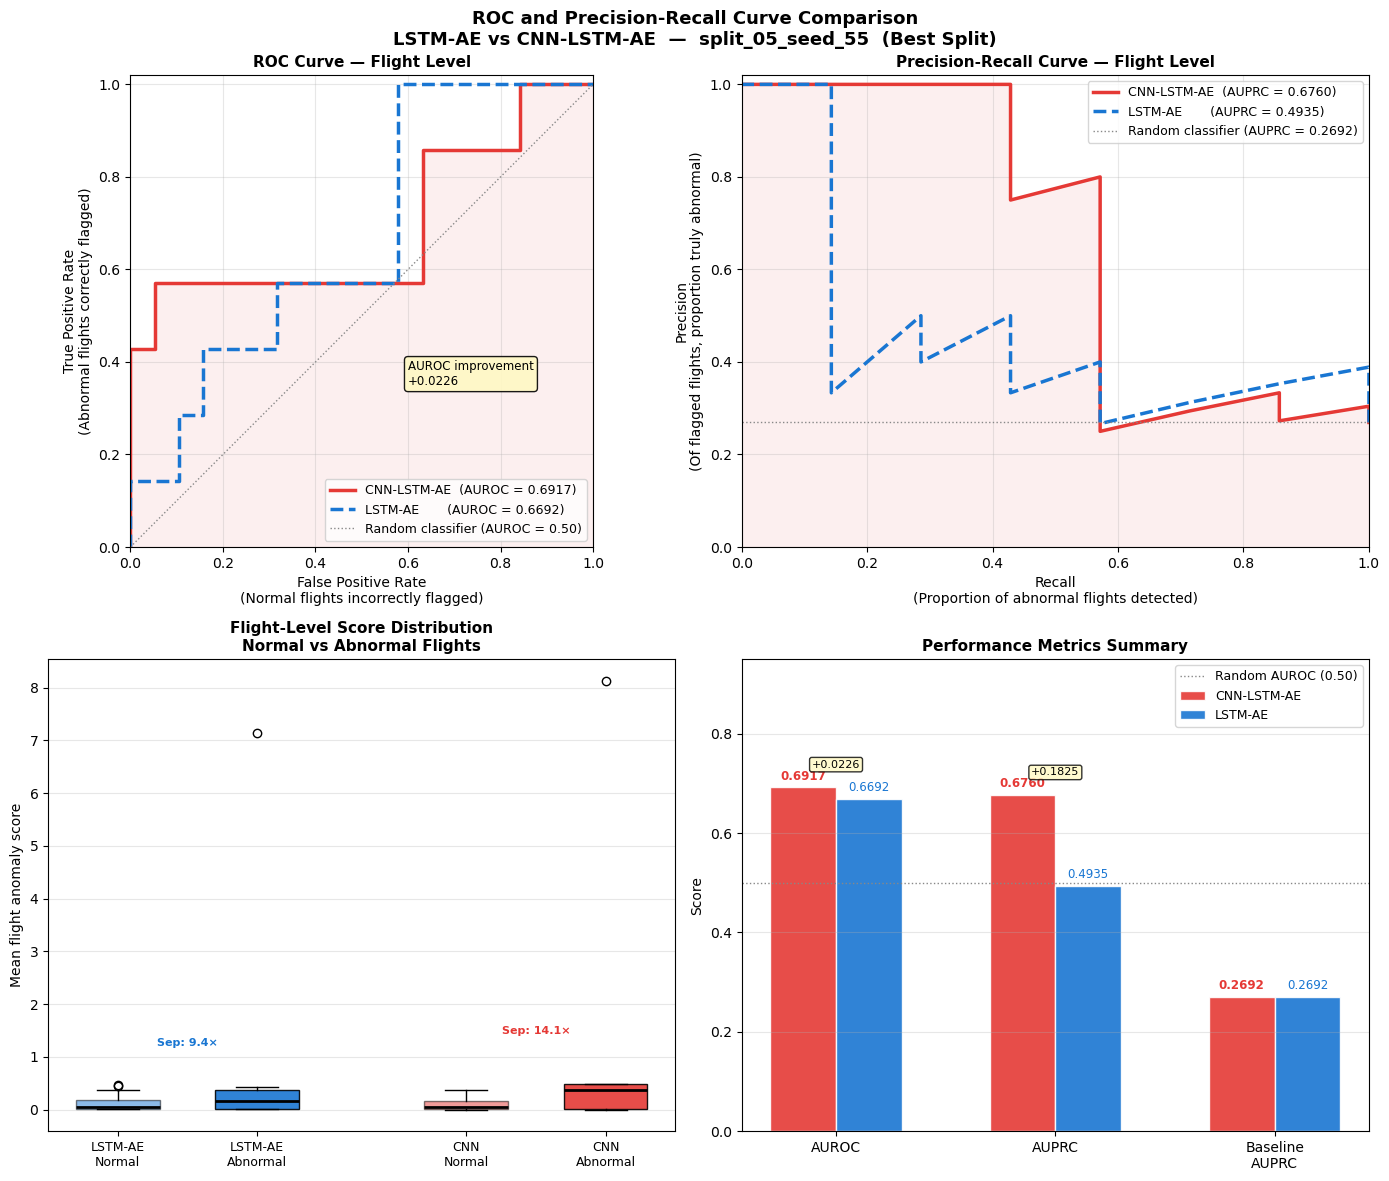

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed/plots/roc_pr_comparison_split_05_seed_55.png


In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(
    f"ROC and Precision-Recall Curve Comparison\n"
    f"LSTM-AE vs CNN-LSTM-AE  —  {SPLIT_NAME}  (Best Split)",
    fontsize=13, fontweight="bold"
)

C_CNN  = "#E53935"   # red
C_LSTM = "#1976D2"   # blue
C_REF  = "#888888"   # grey reference

# ── Panel 1: ROC Curve ────────────────────────────────────────
ax = axes[0, 0]
ax.plot(cnn_fpr,  cnn_tpr,
        color=C_CNN,  linewidth=2.5,
        label=f"CNN-LSTM-AE  (AUROC = {cnn_auroc:.4f})")
ax.plot(lstm_fpr, lstm_tpr,
        color=C_LSTM, linewidth=2.5, linestyle="--",
        label=f"LSTM-AE       (AUROC = {lstm_auroc:.4f})")
ax.plot([0, 1], [0, 1],
        color=C_REF, linewidth=1, linestyle=":",
        label="Random classifier (AUROC = 0.50)")

# Shade area under CNN curve
ax.fill_between(cnn_fpr, cnn_tpr, alpha=0.08, color=C_CNN)

ax.set_xlabel("False Positive Rate\n(Normal flights incorrectly flagged)", fontsize=10)
ax.set_ylabel("True Positive Rate\n(Abnormal flights correctly flagged)", fontsize=10)
ax.set_title("ROC Curve — Flight Level", fontsize=11, fontweight="bold")
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_aspect("equal")

# Annotate improvement
ax.annotate(
    f"AUROC improvement\n{cnn_auroc - lstm_auroc:+.4f}",
    xy=(0.6, 0.35), fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFF9C4", alpha=0.9)
)
# ── Panel 2: Precision-Recall Curve ──────────────────────────
ax = axes[0, 1]
ax.plot(cnn_rec,  cnn_prec,
        color=C_CNN,  linewidth=2.5,
        label=f"CNN-LSTM-AE  (AUPRC = {cnn_auprc:.4f})")
ax.plot(lstm_rec, lstm_prec,
        color=C_LSTM, linewidth=2.5, linestyle="--",
        label=f"LSTM-AE       (AUPRC = {lstm_auprc:.4f})")
ax.axhline(baseline_auprc, color=C_REF, linewidth=1, linestyle=":",
           label=f"Random classifier (AUPRC = {baseline_auprc:.4f})")

ax.fill_between(cnn_rec, cnn_prec, alpha=0.08, color=C_CNN)

ax.set_xlabel("Recall\n(Proportion of abnormal flights detected)", fontsize=10)
ax.set_ylabel("Precision\n(Of flagged flights, proportion truly abnormal)", fontsize=10)
ax.set_title("Precision-Recall Curve — Flight Level", fontsize=11, fontweight="bold")
ax.legend(fontsize=9, loc="upper right")
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
# ── Panel 3: Anomaly score distributions ──────────────────────
ax = axes[1, 0]

# CNN-LSTM-AE
cnn_normal  = cnn_flights.loc[cnn_flights["binary_label"]==0, "mean_score"]
cnn_abnormal= cnn_flights.loc[cnn_flights["binary_label"]==1, "mean_score"]

# LSTM-AE
lstm_normal  = lstm_flights.loc[lstm_flights["binary_label"]==0, "mean_score"]
lstm_abnormal= lstm_flights.loc[lstm_flights["binary_label"]==1, "mean_score"]

positions = [1, 2, 3.5, 4.5]
data      = [lstm_normal, lstm_abnormal, cnn_normal, cnn_abnormal]
labels    = ["LSTM-AE\nNormal", "LSTM-AE\nAbnormal",
             "CNN\nNormal",     "CNN\nAbnormal"]
colors_bp = [C_LSTM, C_LSTM, C_CNN, C_CNN]
alphas    = [0.5, 0.9, 0.5, 0.9]

bp = ax.boxplot(data, positions=positions, widths=0.6,
                patch_artist=True, notch=False,
                medianprops=dict(color="black", linewidth=2))

for patch, col, al in zip(bp["boxes"], colors_bp, alphas):
    patch.set_facecolor(col)
    patch.set_alpha(al)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Mean flight anomaly score", fontsize=10)
ax.set_title("Flight-Level Score Distribution\nNormal vs Abnormal Flights", fontsize=11,
             fontweight="bold")
ax.grid(True, alpha=0.3, axis="y")


for model, norm, abn, xpos, col in [
    ("LSTM-AE",    lstm_normal.mean(), lstm_abnormal.mean(), 1.5,  C_LSTM),
    ("CNN",        cnn_normal.mean(),  cnn_abnormal.mean(),  4.0,  C_CNN),
]:
    sep = abn / norm if norm > 0 else 0
    ax.annotate(
        f"Sep: {sep:.1f}×",
        xy=(xpos, max(abn, norm) * 1.05),
        ha="center", fontsize=8, color=col, fontweight="bold"
    )
    # ── Panel 4: Summary bar chart ────────────────────────────────
ax = axes[1, 1]

metrics      = ["AUROC", "AUPRC", "Baseline\nAUPRC"]
cnn_vals     = [cnn_auroc,  cnn_auprc,  baseline_auprc]
lstm_vals    = [lstm_auroc, lstm_auprc, baseline_auprc]

x   = np.arange(len(metrics))
w   = 0.3
b1  = ax.bar(x - w/2, cnn_vals,  w, color=C_CNN,  label="CNN-LSTM-AE",
             edgecolor="white", alpha=0.9)
b2  = ax.bar(x + w/2, lstm_vals, w, color=C_LSTM, label="LSTM-AE",
             edgecolor="white", alpha=0.9)

for bar, val in zip(b1, cnn_vals):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.01,
            f"{val:.4f}", ha="center", va="bottom",
            fontsize=8.5, color=C_CNN, fontweight="bold")
for bar, val in zip(b2, lstm_vals):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.01,
            f"{val:.4f}", ha="center", va="bottom",
            fontsize=8.5, color=C_LSTM)

ax.axhline(0.5, color=C_REF, linewidth=1, linestyle=":",
           label="Random AUROC (0.50)")
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10)
ax.set_ylabel("Score", fontsize=10)
ax.set_ylim(0, 0.95)
ax.set_title("Performance Metrics Summary", fontsize=11, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

#Improvement annotations
for i, (cnn_v, lstm_v) in enumerate(zip(cnn_vals[:2], lstm_vals[:2])):
    diff = cnn_v - lstm_v
    ax.annotate(
        f"{diff:+.4f}",
        xy=(i, max(cnn_v, lstm_v) + 0.04),
        ha="center", fontsize=8, color="black",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#FFF9C4", alpha=0.8)
    )

plt.tight_layout()
plot_path = PLOT_DIR / f"roc_pr_comparison_{SPLIT_NAME}.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

In [ ]:
print("=" * 65)
print(f"ROC CURVE COMPARISON SUMMARY — {SPLIT_NAME}")
print("=" * 65)
print(f"\nFlight-level evaluation:")
print(f"  Normal flights   : {(lstm_flights['binary_label']==0).sum()}")
print(f"  Abnormal flights : {(lstm_flights['binary_label']==1).sum()}")

print(f"\n{'Metric':<25} {'CNN-LSTM-AE':>12} {'LSTM-AE':>12} {'Improvement':>12}")
print("-" * 65)
print(f"{'AUROC':<25} {cnn_auroc:>12.4f} {lstm_auroc:>12.4f} {cnn_auroc-lstm_auroc:>+12.4f}")
print(f"{'AUPRC':<25} {cnn_auprc:>12.4f} {lstm_auprc:>12.4f} {cnn_auprc-lstm_auprc:>+12.4f}")
print(f"{'Baseline AUPRC':<25} {baseline_auprc:>12.4f} {baseline_auprc:>12.4f} {'—':>12}")
print(f"{'AUPRC vs baseline':<25} {cnn_auprc-baseline_auprc:>+12.4f} {lstm_auprc-baseline_auprc:>+12.4f} {'':>12}")

print(f"\nFlight-level mean scores:")
print(f"  CNN  — Normal: {cnn_flights[cnn_flights['binary_label']==0]['mean_score'].mean():.6f}  "
      f"Abnormal: {cnn_flights[cnn_flights['binary_label']==1]['mean_score'].mean():.6f}  "
      f"Sep: {cnn_flights[cnn_flights['binary_label']==1]['mean_score'].mean() / cnn_flights[cnn_flights['binary_label']==0]['mean_score'].mean():.2f}×")
print(f"  LSTM — Normal: {lstm_flights[lstm_flights['binary_label']==0]['mean_score'].mean():.6f}  "
      f"Abnormal: {lstm_flights[lstm_flights['binary_label']==1]['mean_score'].mean():.6f}  "
      f"Sep: {lstm_flights[lstm_flights['binary_label']==1]['mean_score'].mean() / lstm_flights[lstm_flights['binary_label']==0]['mean_score'].mean():.2f}×")

if cnn_auroc > lstm_auroc:
    print(f"\nCONCLUSION: CNN-LSTM-AE outperforms LSTM-AE on split_05_seed_55")
    print(f"AUROC improvement: {cnn_auroc-lstm_auroc:+.4f}")
    print(f"Use anomaly_score_cnn as the primary feature in notebook 06.")

ROC CURVE COMPARISON SUMMARY — split_05_seed_55

Flight-level evaluation:
  Normal flights   : 19
  Abnormal flights : 7

Metric                     CNN-LSTM-AE      LSTM-AE  Improvement
-----------------------------------------------------------------
AUROC                           0.6917       0.6692      +0.0226
AUPRC                           0.6760       0.4935      +0.1825
Baseline AUPRC                  0.2692       0.2692            —
AUPRC vs baseline              +0.4067      +0.2242             

Flight-level mean scores:
  CNN  — Normal: 0.096338  Abnormal: 1.357726  Sep: 14.09×
  LSTM — Normal: 0.122584  Abnormal: 1.153621  Sep: 9.41×

CONCLUSION: CNN-LSTM-AE outperforms LSTM-AE on split_05_seed_55
AUROC improvement: +0.0226
Use anomaly_score_cnn as the primary feature in notebook 06.
